In [3]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import (
    multinomial, binom, poisson
)

## Binomial Vs Multinomial

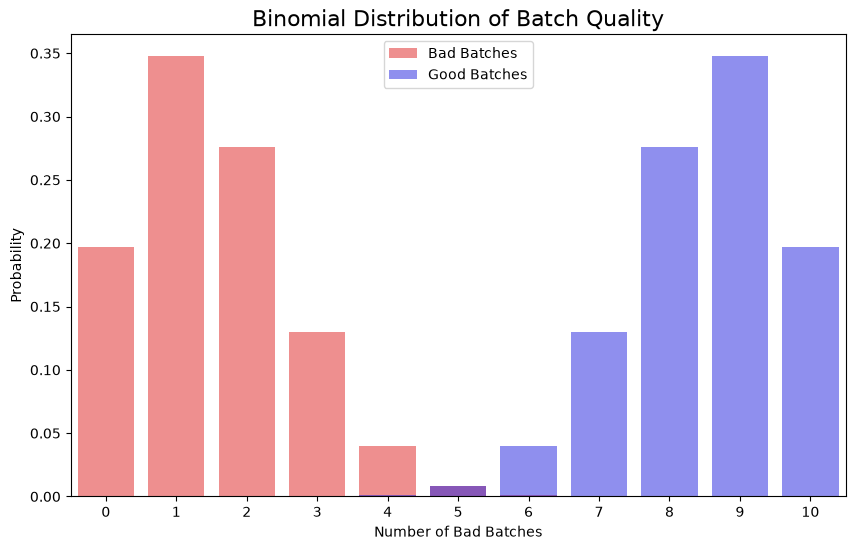

In [11]:
binom_categories = ["good", "bad"]
num_batches = 1000
binom_probs = [0.85, 0.15]
n_trials = 10

#calculate the pmf
pmf_bad = binom.pmf(range(n_trials + 1), n_trials, binom_probs[1])
pmf_good = binom.pmf(range(n_trials + 1), n_trials, binom_probs[0])

# compare the pmfs in bar plot
plt.figure(figsize=(10, 6))
sns.barplot(x=range(n_trials + 1), y=pmf_bad, color='red', alpha=0.5, label='Bad Batches')
sns.barplot(x=range(n_trials + 1), y=pmf_good, color='blue', alpha=0.5, label='Good Batches')
plt.xlabel('Number of Bad Batches')
plt.ylabel('Probability')
plt.title('Binomial Distribution of Batch Quality', fontsize=16)
plt.legend();



##### Notes

The Binomial Distribution is perfect for 2-outcome situations like coin tosses or predicting the probability of a given event out of many (ie the probability your team will win today - three outcomes: Win, Loss and Draw).

However, in complex systems like manufacturing there are multiple outcomes that we care about. This is where the Multinomial shines!

Sampled Data:
   Scratch  Stained  Good  Dented
0        4       15    75       6
1        5        7    85       3
2        2       14    79       5
3        6        4    80      10
4        7        7    83       3



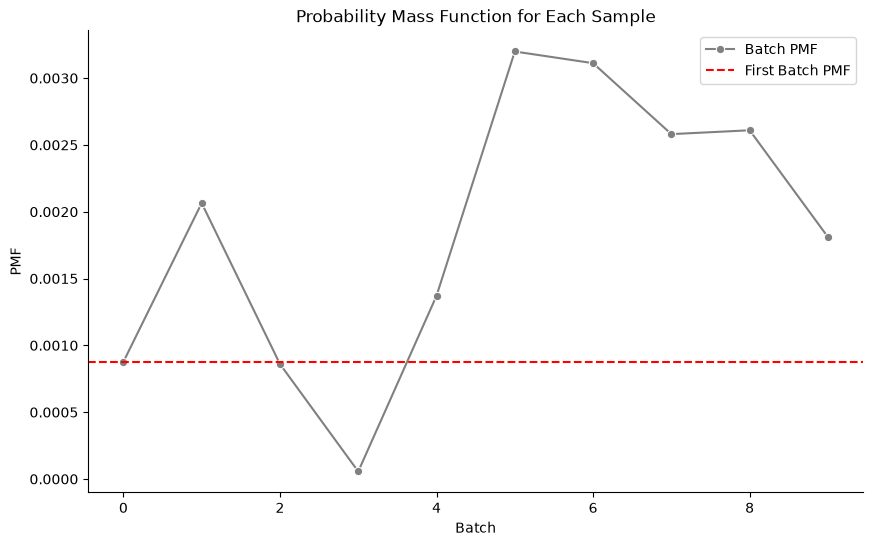

In [61]:
multinom_cats = ["Scratch", "Stained", "Good", "Dented"]
multinom_probs = [0.05, 0.1, 0.8, 0.05]
n_trials = 100 # 1000 items
sample_counts = [50, 100, 800, 50]
num_batches=10

# create sampled data from this distribution
np.random.seed(42)
sample = multinomial.rvs(
    n=n_trials,p=multinom_probs,size=num_batches,random_state=42
    )

# shiow the sampled data
print(f"Sampled Data:\n{pd.DataFrame(sample, columns=multinom_cats).head()}\n")

# now calculate the pmf for each sample
batch_pmf = multinomial.pmf(sample, n=n_trials, p=multinom_probs)

# show results
plt.figure(figsize=(10, 6))
sns.lineplot(
    x=range(num_batches), y=batch_pmf, color='grey', label='Batch PMF', marker='o'
)

plt.axhline(y=batch_pmf[0], color='red', linestyle='--', label='First Batch PMF')
plt.xlabel('Batch')
plt.ylabel('PMF')
plt.title('Probability Mass Function for Each Sample')
plt.legend()
sns.despine()



##### Notes

What we are seeing in the above line plot is the probability of each event happening in each batch. Therefore, we have moved away from one event that we are interested in, and moved into multiple events and their likelihood of happening in each sample -> The PMF calculates the probability of observing that exact combination of counts given a fixed set of baseline probabilities (e.g., 80% good, 10% stained, etc.).

In the plot, the y-axis represents how normal each batch is, which means the higher the probability, the more it conforms to normality of the sample (batch 1). Therefore, anything below the red line would be investigated further as it can be deemed as abnormal batches.